# YOLOv8-seg: eksperimen cepat & inspeksi

Jalankan dari folder proyek yang berisi `dataset/` dan `segmentation.yolo/`.
Empat kombinasi: `{raw, gray_world} x {mask_based, bbox_based}`.
Urutan: cek COCO -> build -> inspeksi sampel -> (verifikasi GT) -> training -> evaluasi -> trace dengan prediksi.

In [1]:
import sys
from itertools import product
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd()))  # agar paket `yolo` bisa di-import

from segmentation.yolo.config import MODES, SPLITS, VARIANTS, Config
from segmentation.yolo.logger import get_logger

cfg = Config(root=Path.cwd())  # ubah bila notebook berada di folder lain
log = get_logger(log_file=cfg.logs_dir / "notebook.log")

## 1. Cek COCO
Pastikan `segmentation_types` = `list` (bukan RLE) dan `category_ids` hanya `1`.

In [2]:
from segmentation.yolo.coco import load_coco, summarize

for split in SPLITS:
    print(split, summarize(load_coco(cfg.annotation_path(split))), "\n")

train {'images': 213, 'annotations': 228, 'images_without_annotation': 1, 'annotations_per_image': {1: 198, 2: 12, 3: 2}, 'segmentation_types': {'dict': 227, 'list': 1}, 'category_ids': {1: 228}, 'image_sizes': {(224, 224): 213}} 

val {'images': 46, 'annotations': 48, 'images_without_annotation': 0, 'annotations_per_image': {1: 45, 3: 1}, 'segmentation_types': {'dict': 48}, 'category_ids': {1: 48}, 'image_sizes': {(224, 224): 46}} 

test {'images': 46, 'annotations': 49, 'images_without_annotation': 0, 'annotations_per_image': {1: 44, 2: 1, 3: 1}, 'segmentation_types': {'dict': 48, 'list': 1}, 'category_ids': {1: 49}, 'image_sizes': {(224, 224): 46}} 



## 2. Build dataset
Satu kombinasi dulu untuk uji; semua kombinasi di sel berikutnya.

In [3]:
from segmentation.yolo.dataset_builder import build_dataset

build_dataset(cfg, "raw", "bbox_based", log=log)

10:08:38 | INFO    | >> Build raw/bbox_based/train
10:08:42 | INFO    | train: 213 sampel, 323 polygon, 1 tanpa polygon (background)
10:08:42 | INFO    | OK Build raw/bbox_based/train (3.6 dtk)
10:08:42 | INFO    | >> Build raw/bbox_based/val
10:08:43 | INFO    | val: 46 sampel, 59 polygon, 0 tanpa polygon (background)
10:08:43 | INFO    | OK Build raw/bbox_based/val (0.7 dtk)
10:08:43 | INFO    | >> Build raw/bbox_based/test
10:08:43 | INFO    | test: 46 sampel, 74 polygon, 0 tanpa polygon (background)
10:08:43 | INFO    | OK Build raw/bbox_based/test (0.8 dtk)
10:08:43 | INFO    | Dataset siap: D:\projects\1-riset-fekal-ayam\segmentation\yolo\yolo_data\raw_bbox_based (305 sampel)


WindowsPath('D:/projects/1-riset-fekal-ayam/segmentation/yolo/yolo_data/raw_bbox_based')

In [4]:
# Semua kombinasi (jalankan setelah hasil inspeksi di bawah terlihat benar)
for variant, mode in product(VARIANTS, MODES):
    build_dataset(cfg, variant, mode, log=log)

10:09:28 | INFO    | >> Build raw/mask_based/train
10:09:29 | INFO    | train: 213 sampel, 323 polygon, 1 tanpa polygon (background)
10:09:29 | INFO    | OK Build raw/mask_based/train (1.4 dtk)
10:09:29 | INFO    | >> Build raw/mask_based/val
10:09:30 | INFO    | val: 46 sampel, 59 polygon, 0 tanpa polygon (background)
10:09:30 | INFO    | OK Build raw/mask_based/val (0.3 dtk)
10:09:30 | INFO    | >> Build raw/mask_based/test
10:09:30 | INFO    | test: 46 sampel, 74 polygon, 0 tanpa polygon (background)
10:09:30 | INFO    | OK Build raw/mask_based/test (0.3 dtk)
10:09:30 | INFO    | Dataset siap: D:\projects\1-riset-fekal-ayam\segmentation\yolo\yolo_data\raw_mask_based (305 sampel)
10:09:30 | INFO    | >> Build raw/bbox_based/train
10:09:31 | INFO    | train: 213 sampel, 323 polygon, 1 tanpa polygon (background)
10:09:31 | INFO    | OK Build raw/bbox_based/train (1.2 dtk)
10:09:31 | INFO    | >> Build raw/bbox_based/val
10:09:31 | INFO    | val: 46 sampel, 59 polygon, 0 tanpa polygon (

## 3. Inspeksi sampel & riwayatnya
`describe` = riwayat teks; `trace` = visualisasi mentah -> varian -> input model (+GT).

[train/KGL_0000]
1. Citra mentah  : dataset/raw/KGL_0000.jpg (224x224)
2. Varian warna  : raw -> dataset/raw/KGL_0000.jpg
3. Crop          : x=60 y=35 w=99 h=189 (union bbox anotasi)
4. Resize        : 99x189 -> 512x512 (skala x5.17, y2.71)
5. Keluaran      : segmentation/yolo/yolo_data/raw_bbox_based/images/train/KGL_0000.jpg + segmentation/yolo/yolo_data/raw_bbox_based/labels/train/KGL_0000.txt (2 polygon)
6. Pemetaan balik: masker 512x512 -> 224x224 via restore_mask()


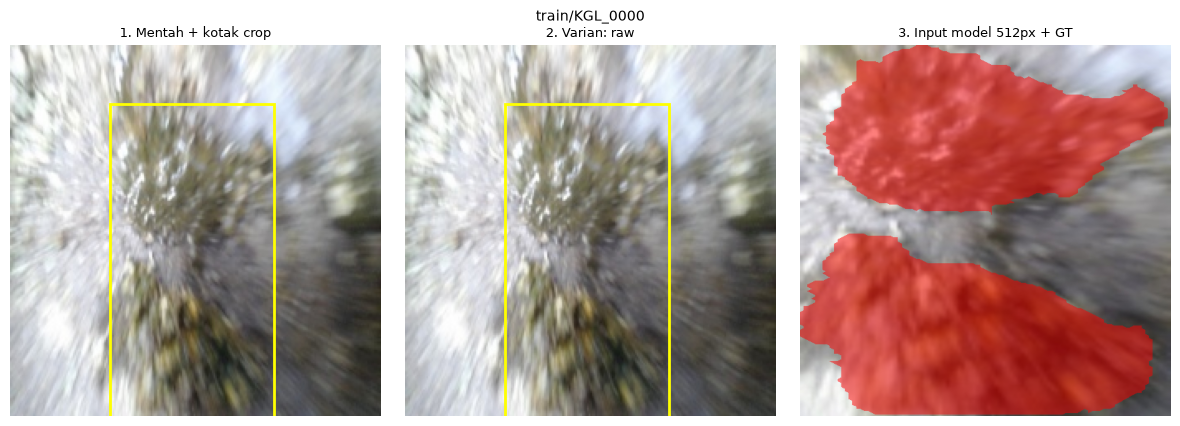

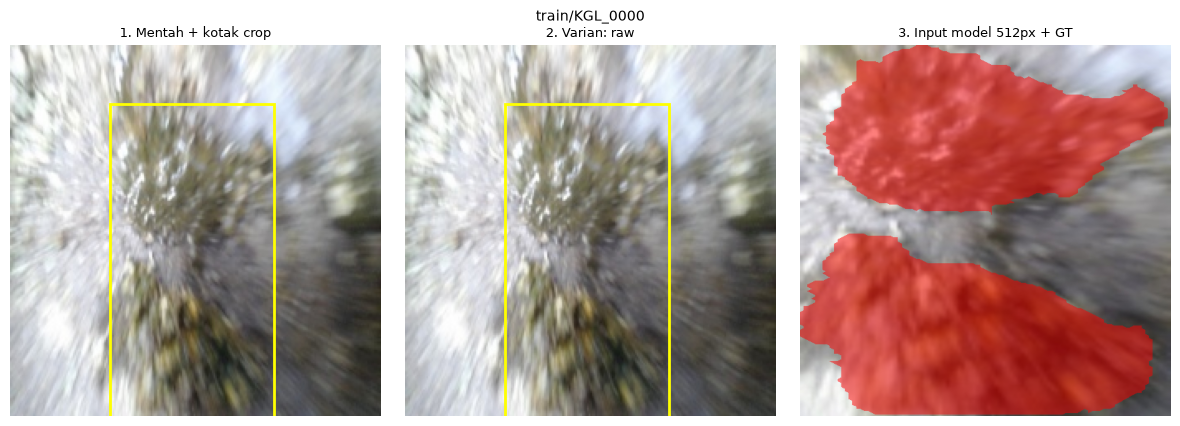

In [5]:
from segmentation.yolo.history import describe, load_manifest, trace

manifest = load_manifest(cfg.dataset_dir("raw", "bbox_based"))
multi = [r for r in manifest.values() if r.n_polygons > 1]
record = multi[0] if multi else next(iter(manifest.values()))

print("\n".join(describe(record)))
trace(cfg, record)

In [6]:
# Sampel yang memicu fallback atau tanpa polygon (perlu dicek manual)
columns = ["key", "n_polygons", "crop_fallback", "crop_box"]
rows = [
    {"key": r.key, "n_polygons": r.n_polygons, "crop_fallback": r.crop_fallback, "crop_box": r.crop_box}
    for r in manifest.values()
    if r.crop_fallback or r.n_polygons == 0
]
pd.DataFrame(rows, columns=columns)

,key,n_polygons,crop_fallback,crop_box
0,train/KGL_0116,0,True,"(0, 0, 224, 224)"


## 4. Verifikasi GT: polygon JSON vs `rawMask`
Jika U-Net memakai `rawMask/`, pastikan kedua sumber GT setara. IoU per gambar harus mendekati 1.0.

In [7]:
import cv2

from segmentation.yolo.coco import group_by_image
from segmentation.yolo.evaluation import binary_scores, ground_truth_mask

split = "val"
coco = load_coco(cfg.annotation_path(split))
anns_by_image = group_by_image(coco)

ious = {}
for info in coco["images"]:
    stem = Path(info["file_name"]).stem
    mask = cv2.imread(str(cfg.root / "dataset" / "rawMask" / split / f"{stem}.png"), cv2.IMREAD_GRAYSCALE)
    assert mask is not None, f"rawMask tidak ditemukan untuk {stem}"
    gt = ground_truth_mask(anns_by_image.get(info["id"], []), info["height"], info["width"])
    ious[stem] = binary_scores(gt, (mask > 127).astype("uint8") * 255)["iou"]

ious = pd.Series(ious)
print(ious.describe())
ious.nsmallest(5)

count    46.000000
mean      0.998396
std       0.007955
min       0.945933
25%       0.999408
50%       1.000000
75%       1.000000
max       1.000000
dtype: float64


KGL_0034    0.945933
KGL_0123    0.996077
KGL_0138    0.997166
KGL_0050    0.997262
KGL_0008    0.998165
dtype: float64

## 5. Training
Uji cepat memakai `name=` terpisah agar tidak menimpa run penuh.

In [8]:
from segmentation.yolo.training import train

# Uji cepat: 3 epoch (folder run: runs/smoke_raw_mask_based)
build_dataset(cfg, "raw", "mask_based", log=log)
train(cfg, "raw", "mask_based", epochs=3, batch=8, name="smoke_raw_mask_based", log=log)

10:21:43 | INFO    | >> Build raw/mask_based/train
10:21:45 | INFO    | train: 213 sampel, 323 polygon, 1 tanpa polygon (background)
10:21:45 | INFO    | OK Build raw/mask_based/train (1.4 dtk)
10:21:45 | INFO    | >> Build raw/mask_based/val
10:21:45 | INFO    | val: 46 sampel, 59 polygon, 0 tanpa polygon (background)
10:21:45 | INFO    | OK Build raw/mask_based/val (0.3 dtk)
10:21:45 | INFO    | >> Build raw/mask_based/test
10:21:45 | INFO    | test: 46 sampel, 74 polygon, 0 tanpa polygon (background)
10:21:45 | INFO    | OK Build raw/mask_based/test (0.3 dtk)
10:21:45 | INFO    | Dataset siap: D:\projects\1-riset-fekal-ayam\segmentation\yolo\yolo_data\raw_mask_based (305 sampel)
10:21:54 | INFO    | >> Training smoke_raw_mask_based
New https://pypi.org/project/ultralytics/8.4.199 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.177  Python-3.14.7 torch-2.13.0 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1

WindowsPath('D:/projects/1-riset-fekal-ayam/segmentation/yolo/runs/smoke_raw_mask_based/weights/best.pt')

In [9]:
# Training penuh semua kombinasi (pastikan semua dataset sudah di-build)
for variant, mode in product(VARIANTS, MODES):
    train(cfg, variant, mode, epochs=100, batch=16, log=log)

10:32:22 | INFO    | >> Training raw_mask_based
New https://pypi.org/project/ultralytics/8.4.199 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.177  Python-3.14.7 torch-2.13.0 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\projects\1-riset-fekal-ayam\segmentation\yolo\yolo_data\raw_mask_based\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=

AcceleratorError: CUDA error: an illegal memory access was encountered
Search for `cudaErrorIllegalAddress' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1


## 6. Evaluasi
- `mask_map50*`, `box_map50`: metrik instance Ultralytics (di ruang input model).
- `semantic_iou`, `semantic_dice`: semua instance digabung, dipetakan balik ke ukuran asli, dibandingkan dengan GT penuh. Gunakan kolom ini untuk membandingkan keempat kombinasi (dan dengan U-Net).

In [ ]:
from segmentation.yolo.evaluation import evaluate_semantic
from segmentation.yolo.training import validate

rows = []
for variant, mode in product(VARIANTS, MODES):
    weights = cfg.best_weights(variant, mode)
    if not weights.exists():
        continue  # kombinasi ini belum dilatih
    rows.append({
        "variant": variant, "mode": mode,
        **validate(cfg, weights, variant, mode, "test", log=log),
        **evaluate_semantic(cfg, weights, variant, mode, "test", log=log),
    })
pd.DataFrame(rows)

## 7. Trace dengan prediksi
Dari citra mentah sampai prediksi dipetakan balik ke koordinat citra asli.

In [ ]:
from ultralytics import YOLO

from segmentation.yolo.evaluation import predict_mask

variant, mode = "raw", "bbox_based"
model = YOLO(str(cfg.best_weights(variant, mode)))
manifest = load_manifest(cfg.dataset_dir(variant, mode))

key = next(k for k in manifest if k.startswith("test/"))  # ganti sesuai kebutuhan
record = manifest[key]
print("\n".join(describe(record)))
trace(cfg, record, pred_mask=predict_mask(model, cfg, record), save_to=cfg.root / "trace_demo.png");

## Catatan
- `trace` merekam transformasi geometri deterministik (crop + resize). Augmentasi saat training (mosaic, flip, HSV) tidak dicatat dan tidak relevan untuk inferensi.
- Pada `bbox_based`, crop memakai bbox *ground truth* (oracle), termasuk di test. Skornya batas atas, bukan performa deployment.
- Log tahapan: `logs/*.log`. Kurva dan metrik per epoch dari Ultralytics: `runs/<nama>/results.csv`.